# From prices to returns and growth

A price rises from 100 to 110, falls to 99, then finishes at 118.8. Did the
successive percentage changes produce the same answer as comparing the first
and last prices? This notebook connects those two calculations.

You will calculate a return, reconstruct a price path by compounding, and decide
when logarithmic returns can be added. You need basic Python lists, division,
and percentages. A decimal of `0.10` means 10%, not 0.10%. No calculus is needed.

All prices here are invented teaching inputs. They are not an investment,
historical market performance, or a prediction. These examples describe price
changes and omit dividends, fees, taxes, and external cash flows.

## Setup

From the repository root, run `uv sync --extra notebooks`, then open this file
with a Jupyter-capable editor using the repository's `.venv`.
The command `uv run --extra notebooks python tools/verify_notebooks.py` runs
both notebooks without needing an editor. In an installed environment, select
that environment's Python kernel. Run the cells in order.

In [1]:
import math

import matplotlib.pyplot as plt

from quantchapter_returns import (
    cumulative_growth,
    log_returns,
    simple_returns,
    total_return,
)

plt.rcParams.update(
    {
        "font.family": "DejaVu Sans",
        "font.size": 11,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "figure.dpi": 110,
    }
)
prices = (100.0, 110.0, 99.0, 118.8)
print("Synthetic prices:", prices)

Synthetic prices: (100.0, 110.0, 99.0, 118.8)


## Measure a change relative to its starting price

The first gain is 10 price units. To compare it with a gain on a differently
priced series, divide by the amount at the start: $10/100=0.10$, or 10%.

Write $P_t$ for the price at observation $t$, and $P_{t-1}$ for the immediately
previous price. The subscript identifies an observation, not a power. A **simple
return** is the change divided by its own starting price:

$$r_t=\frac{P_t-P_{t-1}}{P_{t-1}}=\frac{P_t}{P_{t-1}}-1.$$

For the second change, the starting price is now 110. The loss is 11, so its
return is $-11/110=-0.10$. The final change is $19.8/99=0.20$. There are three
returns from four prices: the first price has no earlier observation here.

The function performs these adjacent comparisons. It requires finite, strictly
positive prices; it neither fills missing observations nor sorts them for you.

In [2]:
returns = simple_returns(prices)
for start, end, result in zip(prices[:-1], prices[1:], returns, strict=True):
    print(f"{start:6.1f} -> {end:6.1f}: {result:+.2%}")
assert all(
    math.isclose(a, b, abs_tol=1e-14) for a, b in zip(returns, (0.10, -0.10, 0.20), strict=True)
)

 100.0 ->  110.0: +10.00%
 110.0 ->   99.0: -10.00%
  99.0 ->  118.8: +20.00%


**Check the denominator.** A separate price falls from 200 to 180. Choose the
return: (A) $-10\%$, (B) $-11.11\%$, or (C) $+10\%$.

**Worked comparison:** A is correct. The change is $180-200=-20$ and the starting
price is 200, so $-20/200=-0.10$. B divides by the ending price; C loses the sign.

## Rebuild the path one change at a time

A 10% gain turns each starting unit into 1.10 units. A subsequent 10% loss
multiplies the new amount by 0.90. Starting with one unit therefore gives

$$1\times1.10\times0.90=0.99.$$

Equal positive and negative percentages do not cancel because they apply to
different amounts. Adding the two percentages would hide the 1% loss.

**Compounding** means carrying the result of one period into the next. With
initial wealth $W_0$, the rule is $W_t=W_{t-1}(1+r_t)$. `cumulative_growth`
returns the initial value as well as every later value, so four prices and three
returns produce four growth values.

In [3]:
growth = cumulative_growth(returns)
print("Growth of one unit:", tuple(round(value, 6) for value in growth))
print(f"Compounded total return: {growth[-1] / growth[0] - 1:.2%}")
print(f"First-to-last price return: {total_return(prices):.2%}")
assert math.isclose(growth[-1], 1.188, abs_tol=1e-14)
assert math.isclose(growth[-1] - 1, total_return(prices), abs_tol=1e-14)

Growth of one unit: (1.0, 1.1, 0.99, 1.188)
Compounded total return: 18.80%
First-to-last price return: 18.80%


The growth path is $1, 1.10, 0.99, 1.188$: the final gain is 18.8%.
The shortcut works because consecutive price ratios cancel their intermediate
prices:

$$\frac{110}{100}\times\frac{99}{110}\times\frac{118.8}{99}
=\frac{118.8}{100}.$$

The sum $10\%-10\%+20\%=20\%$ does not reproduce the result. The multiplication
does. This agreement provides an independent way to check a calculation.

The next figure places the four exact growth values at their observation
numbers. Lines connect consecutive observations; they do not reveal what
happened between them. The baseline is one starting unit.

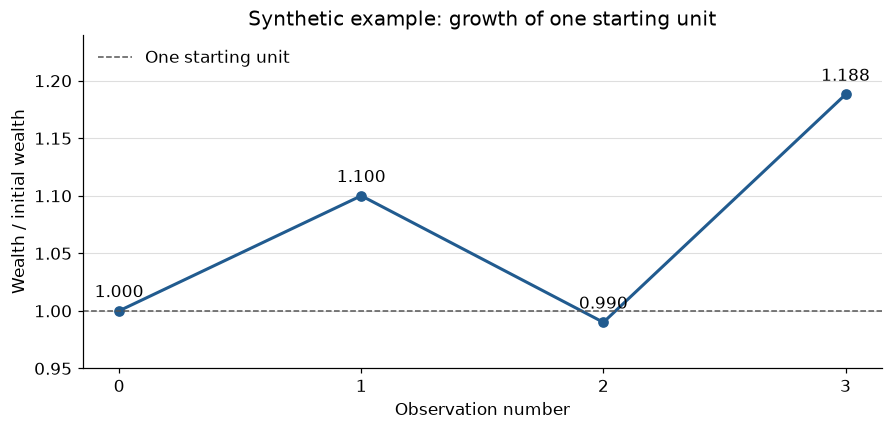

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.8), layout="constrained")
observations = tuple(range(len(growth)))
ax.plot(observations, growth, color="#215b8f", marker="o", linewidth=2)
ax.axhline(1.0, color="#555555", linestyle="--", linewidth=1, label="One starting unit")
for position, value in zip(observations, growth, strict=True):
    ax.annotate(
        f"{value:.3f}", (position, value), xytext=(0, 9), textcoords="offset points", ha="center"
    )
ax.set(
    xticks=observations,
    xlabel="Observation number",
    ylabel="Wealth / initial wealth",
    ylim=(0.95, 1.24),
    title="Synthetic example: growth of one starting unit",
)
ax.legend(loc="upper left", frameon=False)
ax.grid(axis="y", color="#dedede", linewidth=0.7)
plt.show()

The path ends above its start, but observation 2 is below the starting amount.
An endpoint comparison and the route between endpoints answer different
questions. We will use that distinction in the next notebook.

## Use logarithms to turn multiplication into addition

A logarithm is a transformation with the rule $\log(ab)=\log(a)+\log(b)$
for positive $a$ and $b$. Here `log` means the natural logarithm, which Python
computes with `math.log`. You do not need its calculus to use this rule.

For a price ratio, define a **logarithmic return** by

$$\ell_t=\log\!\left(\frac{P_t}{P_{t-1}}\right)=\log(1+r_t).$$

Logarithmic returns can be added across consecutive observations because they
are logarithms of the same ratios that compounding multiplies. To recover the
total simple return, undo the logarithm with the exponential:

$$\text{total simple return}=\exp\!\left(\sum_t\ell_t\right)-1.$$

The summation symbol means add the individual logarithmic returns. A log return
of about 0.09531 corresponds to a simple gain of 10%; they are different measures.

In [5]:
log_changes = log_returns(prices)
print("Logarithmic returns:", tuple(round(value, 6) for value in log_changes))
recovered_total = math.expm1(math.fsum(log_changes))
print(f"Total simple return recovered from logs: {recovered_total:.2%}")
assert math.isclose(recovered_total, 0.188, abs_tol=1e-14)
assert math.isclose(math.fsum(log_changes), math.log(prices[-1] / prices[0]), abs_tol=1e-14)

Logarithmic returns: (0.09531, -0.105361, 0.182322)
Total simple return recovered from logs: 18.80%


**Independent attempt.** For prices $(50, 60, 48)$, choose the total simple return:
(A) $0\%$, (B) $-4\%$, or (C) $-20\%$. Then compare with the calculation below.

**Worked comparison:** the first return is $10/50=20\%$ and the second is
$-12/60=-20\%$. Multiplying $1.20\times0.80=0.96$ leaves a 4% loss, so B is
correct. The endpoint check is $48/50-1=-0.04$. Adding percentages gives A
incorrectly; C describes only the last change.

## Checks and next steps

The final cell verifies the fresh case with the public API. All checks use a
small floating-point tolerance because computers store most decimals only
approximately. These assertions check calculations, not learner mastery.

In [6]:
fresh_prices = (50.0, 60.0, 48.0)
fresh_returns = simple_returns(fresh_prices)
assert math.isclose(total_return(fresh_prices), -0.04, abs_tol=1e-14)
assert math.isclose(cumulative_growth(fresh_returns)[-1], 0.96, abs_tol=1e-14)
assert math.isclose(math.expm1(math.fsum(log_returns(fresh_prices))), -0.04, abs_tol=1e-14)
print("Fresh case: 20% gain, 20% loss, 4% total loss. Checks passed.")

Fresh case: 20% gain, 20% loss, 4% total loss. Checks passed.


Continue with [drawdown and volatility](02_drawdown_and_volatility.ipynb).
That notebook asks how a positive total return can coexist with a substantial
intermediate loss. The [mathematics reference](../docs/mathematics.md) records
the precise conventions and numerical limits used by the package.